# 01 — Dataset dan EDA

Notebook ini memeriksa dataset Batik Banyumasan sebelum eksperimen dimulai:

1. membaca semua file dan mengurai nama file menjadi `motif`, `origin_id`, dan `aug_type`;
2. audit: jumlah per kelas dan per jenis augmentasi, kelengkapan 9 file per foto asli, ukuran citra, mode warna, file rusak;
3. visualisasi: distribusi kelas, satu foto asli beserta 8 augmentasinya, dan contoh foto asli tiap kelas;
4. bahan untuk memilih **kelas pantauan H3** (kelas berpola paling berarah).

Data uji tidak boleh dipakai untuk keputusan apa pun. Karena split bersifat deterministik (`random_state=42`), notebook ini sudah memanggil `make_split()` hanya untuk mengetahui `origin_id` mana yang termasuk data latih. Semua contoh gambar dan perhitungan untuk pemilihan kelas H3 diambil **dari data latih saja**. File `results/split.csv` baru dibuat di notebook 02.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from src import config
from src.data import build_index, add_image_info, audit, make_split

FIG_DIR = config.FIGURES_DIR / "01_dataset"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 120)
t0 = time.time()

## 1. Indeks file

Label diambil dari **nama folder**. Nama file diurai dengan pola `Motif (idx)[_Aug].jpg`:
`origin_id = f"{motif}_{idx}"` mengelompokkan foto asli dengan salinan augmentasinya, dan `aug_type` bernilai `original` untuk foto asli.

In [2]:
assert config.RAW_DIR.is_dir(), "Jalankan dulu: uv run python -m src.download_data"
df = build_index()
print(f"{len(df)} file .jpg")
df.head()

5148 file .jpg


,filename,label,motif,idx,origin_id,aug_type,matched,label_consistent
0,Angguran/Angguran (1).jpg,Angguran,Angguran,1,Angguran_1,original,True,True
1,Angguran/Angguran (1)_ChannelShuffle.jpg,Angguran,Angguran,1,Angguran_1,ChannelShuffle,True,True
2,Angguran/Angguran (1)_ElasticTransform.jpg,Angguran,Angguran,1,Angguran_1,ElasticTransform,True,True
3,Angguran/Angguran (1)_FDA.jpg,Angguran,Angguran,1,Angguran_1,FDA,True,True
4,Angguran/Angguran (1)_Flip.jpg,Angguran,Angguran,1,Angguran_1,Flip,True,True


## 2. Informasi citra

Setiap file dibuka dan di-*decode* penuh (`Image.load()`) supaya file yang terpotong atau rusak ikut terdeteksi, bukan hanya header-nya yang dibaca. Langkah ini paling lama di notebook ini.

In [3]:
df = add_image_info(df)
df[["filename", "width", "height", "mode", "corrupt"]].head()

baca citra:   0%|          | 0/5148 [00:00<?, ?it/s]

,filename,width,height,mode,corrupt
0,Angguran/Angguran (1).jpg,512,512,RGB,False
1,Angguran/Angguran (1)_ChannelShuffle.jpg,512,512,RGB,False
2,Angguran/Angguran (1)_ElasticTransform.jpg,512,512,RGB,False
3,Angguran/Angguran (1)_FDA.jpg,512,512,RGB,False
4,Angguran/Angguran (1)_Flip.jpg,512,512,RGB,False


## 3. Audit

In [4]:
rep = audit(df)
counts = pd.DataFrame({
    "total": rep["per_class"],
    "asli": rep["originals_per_class"],
}).fillna(0).astype(int)
counts["augmentasi"] = counts["total"] - counts["asli"]
counts.loc["TOTAL"] = counts.sum()
counts

,total,asli,augmentasi
label,,,
Angguran,468,52,416
Ayam Puger,468,52,416
Jahe Lumbon,468,52,416
Jahe Puger,468,52,416
Jahe Srimpang,468,52,416
Lumbon,468,52,416
Madu Bronto,468,52,416
Pring Sedapur,468,52,416
Puger Galar,468,52,416


In [5]:
print("Jumlah file          :", rep["n_files"], f"(diharapkan {config.EXPECTED_TOTAL})")
print("Jumlah foto asli     :", rep["n_originals"], f"(diharapkan {config.EXPECTED_ORIGINALS})")
print("Jumlah origin_id     :", rep["n_origin_ids"])
print("Tidak cocok pola     :", len(rep["unmatched"]), rep["unmatched"][:10])
print("Label folder != nama :", len(rep["label_mismatch"]), rep["label_mismatch"][:10])
print("Jenis aug tak dikenal:", rep["unknown_aug_types"])
print("File rusak           :", len(rep["corrupt"]), rep["corrupt"][:10])
print("origin_id tanpa asli :", len(rep["origins_without_original"]), rep["origins_without_original"][:10])
print(f"origin_id dengan jumlah file != {config.FILES_PER_ORIGIN}:", len(rep["bad_origins"]))
rep["bad_origins"]

Jumlah file          : 5148 (diharapkan 5148)
Jumlah foto asli     : 572 (diharapkan 572)
Jumlah origin_id     : 572
Tidak cocok pola     : 0 []
Label folder != nama : 0 []
Jenis aug tak dikenal: []
File rusak           : 0 []
origin_id tanpa asli : 0 []
origin_id dengan jumlah file != 9: 0


Series([], dtype: int64)

In [6]:
rep["per_aug_type"].rename("jumlah").to_frame()

,jumlah
aug_type,
original,572
ChannelShuffle,572
ElasticTransform,572
FDA,572
Flip,572
RandomGridShuffle,572
RandomRotate90,572
Sharpen,572
Transpose,572


### Ukuran dan mode warna

Ukuran citra menentukan `IMG_SIZE`. Desain ETS memakai 256×256; kalau ada citra yang lebih kecil dari 256 piksel, ukuran itu perlu dibicarakan dulu karena *upscaling* menambah piksel interpolasi yang bukan tekstur asli.

In [7]:
print("Ukuran (lebar, tinggi) -> jumlah file")
print(rep["sizes"].to_string())
print()
print("Mode warna:")
print(rep["modes"].to_string())

Ukuran (lebar, tinggi) -> jumlah file
width  height
512    512       5148

Mode warna:
mode
RGB    5148


In [8]:
size_by_aug = (
    df[~df["corrupt"]]
    .assign(ukuran=lambda d: d["width"].astype(int).astype(str) + "x" + d["height"].astype(int).astype(str))
    .groupby(["aug_type", "ukuran"]).size().unstack(fill_value=0)
)
size_by_aug

ukuran,512x512
aug_type,
ChannelShuffle,572
ElasticTransform,572
FDA,572
Flip,572
RandomGridShuffle,572
RandomRotate90,572
Sharpen,572
Transpose,572
original,572


In [9]:
side_min = df[["width", "height"]].min(axis=1)
print(f"Sisi terpendek: min={side_min.min()}, median={side_min.median()}, max={side_min.max()}")
print("Citra tidak persegi:", int((df["width"] != df["height"]).sum()))
print(f"Citra dengan sisi < {config.IMG_SIZE}:", int((side_min < config.IMG_SIZE).sum()))

Sisi terpendek: min=512, median=512.0, max=512
Citra tidak persegi: 0
Citra dengan sisi < 256: 0


### Indeks dataset bersih

Audit tidak menemukan file rusak, file dengan nama di luar pola, label yang tidak konsisten, maupun `origin_id` yang tidak lengkap, sehingga tidak ada citra yang dibuang. Hasil audit disimpan sebagai `results/dataset_index.csv`: satu baris per citra dengan label dan metadata yang sudah diperiksa. Notebook berikutnya cukup membaca tabel ini dan tidak perlu mengurai nama file lagi.

In [10]:
clean = df[df["matched"] & df["label_consistent"] & ~df["corrupt"]]
clean = clean[["filename", "label", "origin_id", "idx", "aug_type", "width", "height", "mode"]].copy()
clean[["idx", "width", "height"]] = clean[["idx", "width", "height"]].astype(int)
config.RESULTS_DIR.mkdir(exist_ok=True)
clean.to_csv(config.RESULTS_DIR / "dataset_index.csv", index=False)
print(f"{len(clean)} dari {len(df)} citra disimpan ke results/dataset_index.csv")

5148 dari 5148 citra disimpan ke results/dataset_index.csv


## 4. Distribusi kelas

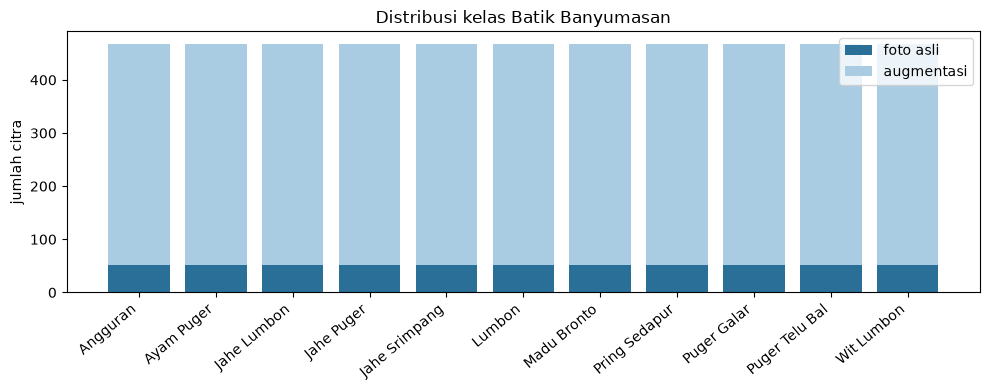

In [11]:
plot_df = counts.drop(index="TOTAL")
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(plot_df.index, plot_df["asli"], label="foto asli", color="#2a6f97")
ax.bar(plot_df.index, plot_df["augmentasi"], bottom=plot_df["asli"], label="augmentasi", color="#a9cce3")
ax.set_ylabel("jumlah citra")
ax.set_title("Distribusi kelas Batik Banyumasan")
ax.tick_params(axis="x", rotation=40)
for lbl in ax.get_xticklabels():
    lbl.set_ha("right")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "distribusi_kelas.png", dpi=150)
plt.show()

## 5. Split per foto asli (hanya untuk memilih contoh dari data latih)

`make_split()` membagi tabel `origin_id` unik 80/20 secara stratified, lalu membuang salinan augmentasi dari grup uji. Di sini hasilnya hanya dipakai untuk menyaring data latih. Penyimpanan `results/split.csv` dilakukan di notebook 02.

In [12]:
split = make_split(df)
train_orig = df.merge(split[split["split"] == "train"][["filename"]], on="filename")
train_orig = train_orig[train_orig["aug_type"] == "original"].reset_index(drop=True)
print(split.groupby(["split", "aug_type"]).size().unstack(fill_value=0).sum(axis=1))
print("Foto asli latih per kelas:", train_orig["label"].value_counts().sort_index().to_dict())

split
test      115
train    4113
dtype: int64
Foto asli latih per kelas: {'Angguran': 42, 'Ayam Puger': 42, 'Jahe Lumbon': 42, 'Jahe Puger': 41, 'Jahe Srimpang': 41, 'Lumbon': 42, 'Madu Bronto': 41, 'Pring Sedapur': 41, 'Puger Galar': 41, 'Puger Telu Bal': 42, 'Wit Lumbon': 42}


## 6. Satu foto asli dan 8 augmentasinya

Gambar ini menunjukkan kenapa split per file berbahaya: `Flip`, `Transpose`, dan `RandomRotate90` adalah kain yang persis sama dengan orientasi berbeda, sehingga model yang melihat salah satunya di data latih praktis sudah "melihat" data uji.

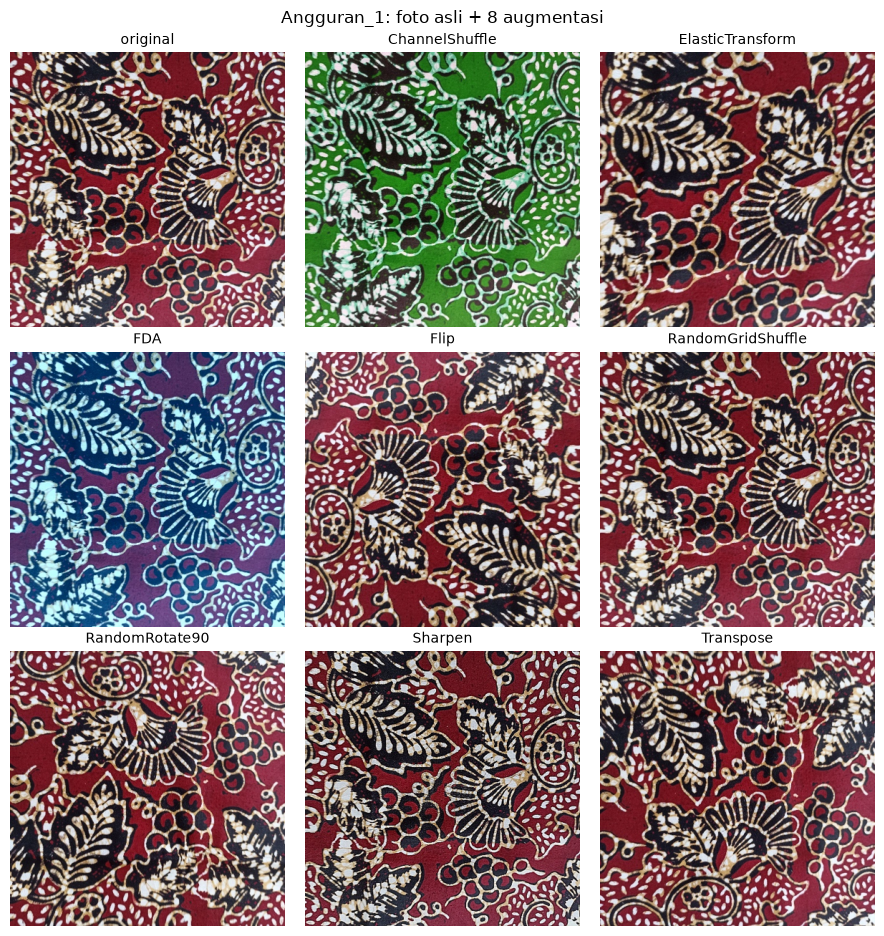

In [13]:
def load_thumb(fn, size=384):
    with Image.open(config.RAW_DIR / fn) as im:
        im = im.convert("RGB")
        im.thumbnail((size, size))
        return np.asarray(im)

example_origin = train_orig.iloc[0]["origin_id"]
group = df[df["origin_id"] == example_origin].copy()
order = ["original", *config.AUG_TYPES]
group = group.set_index("aug_type").reindex(order).reset_index()

fig, axes = plt.subplots(3, 3, figsize=(9, 9.5))
for ax, (_, r) in zip(axes.flat, group.iterrows()):
    if isinstance(r["filename"], str):
        ax.imshow(load_thumb(r["filename"]))
    ax.set_title(r["aug_type"], fontsize=10)
    ax.axis("off")
fig.suptitle(f"{example_origin}: foto asli + 8 augmentasi", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "contoh_augmentasi.png", dpi=150)
plt.show()

## 7. Contoh foto asli per kelas (data latih)

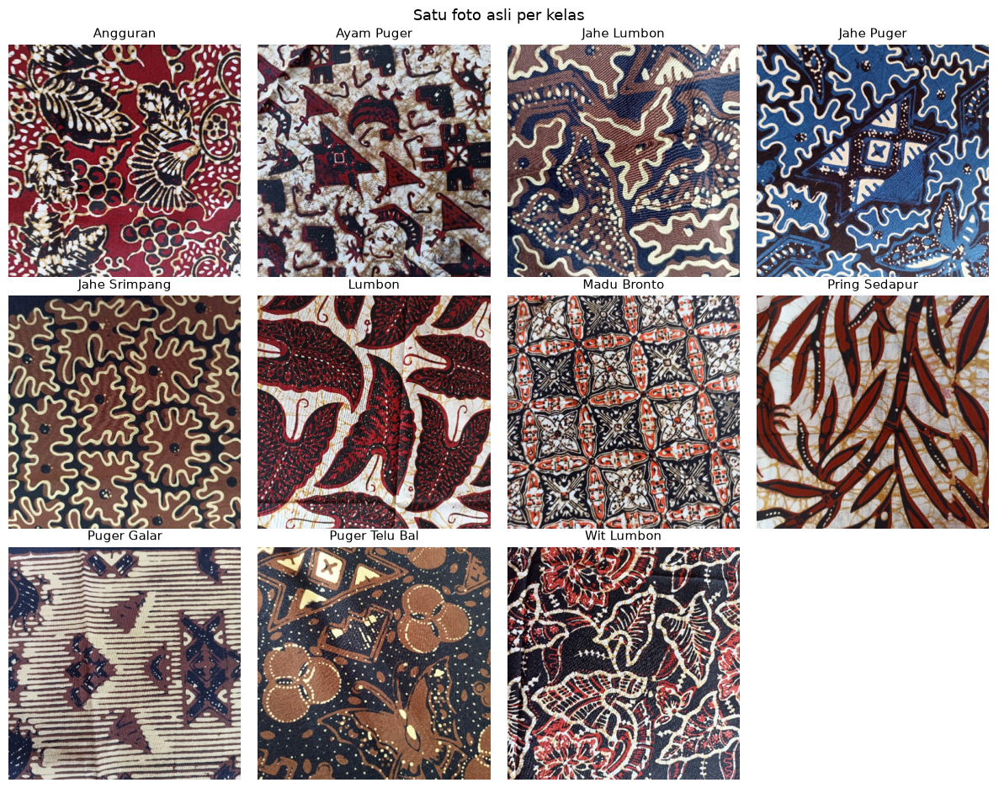

In [14]:
rng = np.random.default_rng(config.SEED)
fig, axes = plt.subplots(3, 4, figsize=(12, 9.5))
for ax, cls in zip(axes.flat, config.CLASSES):
    fn = train_orig[train_orig["label"] == cls]["filename"].sort_values().iloc[0]
    ax.imshow(load_thumb(fn))
    ax.set_title(cls, fontsize=11)
    ax.axis("off")
axes.flat[-1].axis("off")
fig.suptitle("Satu foto asli per kelas", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "contoh_per_kelas.png", dpi=150)
plt.show()

## 8. Bahan pemilihan kelas pantauan H3

H3 menguji apakah GLCM 4 arah (S2) lebih baik daripada GLCM 0° saja (S1). Efeknya diperkirakan paling terlihat pada kelas yang polanya **berarah** (garis atau diagonal dominan), karena GLCM 0° hanya melihat pasangan piksel horizontal dan bisa "buta" terhadap struktur yang arahnya lain.

Pemilihan dilakukan secara **visual**. Sebagai alat bantu, ditampilkan:

1. lembar kontak 6 foto asli latih per kelas, supaya penilaian tidak bergantung pada satu foto;
2. indeks anisotropi sederhana: kontras GLCM dihitung di 4 sudut, lalu dihitung `(maks − min) / rata-rata`. Nilai tinggi berarti tekstur terlihat sangat berbeda tergantung arah, yaitu pola yang berarah. Perhitungan ini kasar (grayscale, resize ke `IMG_SIZE`, kuantisasi 8 level, tanpa CLAHE) dan **hanya memakai foto asli dari data latih**.

Satu catatan: di foto, arah kain di lantai tidak selalu sama antar-foto, jadi motif berarah bisa muncul dengan sudut berbeda di tiap foto. Indeks anisotropi tidak terpengaruh hal ini karena mengambil selisih maks−min di keempat sudut, apa pun sudut dominannya.

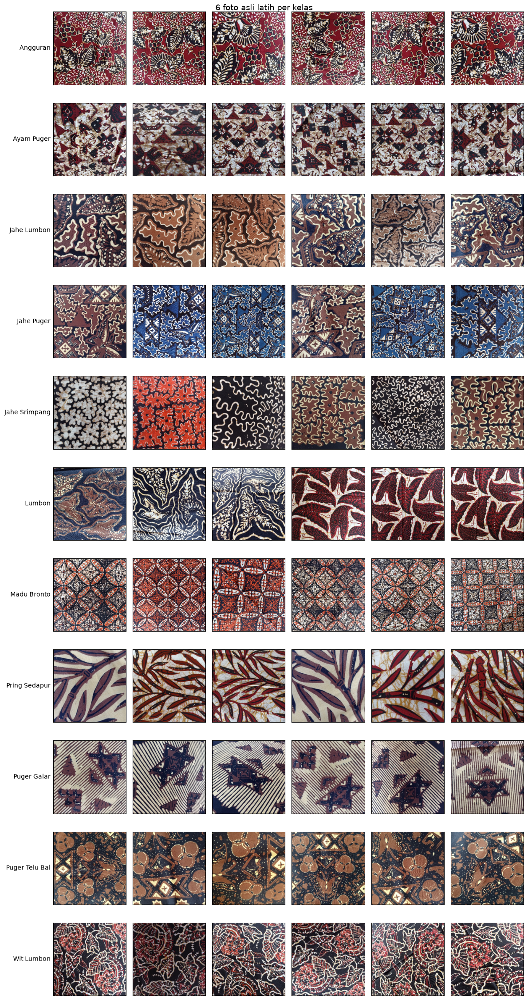

In [15]:
fig, axes = plt.subplots(len(config.CLASSES), 6, figsize=(12, 2.1 * len(config.CLASSES)))
for i, cls in enumerate(config.CLASSES):
    fns = train_orig[train_orig["label"] == cls].sample(6, random_state=config.SEED)["filename"]
    for j, fn in enumerate(fns):
        ax = axes[i, j]
        ax.imshow(load_thumb(fn, size=192))
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(cls, fontsize=10, rotation=0, ha="right", va="center")
fig.suptitle("6 foto asli latih per kelas", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "lembar_kontak_per_kelas.png", dpi=110)
plt.show()

In [16]:
from skimage.feature import graycomatrix, graycoprops
from skimage.transform import resize


def to_gray_uint8(fn, size=config.IMG_SIZE):
    with Image.open(config.RAW_DIR / fn) as im:
        rgb = np.asarray(im.convert("RGB"), dtype=np.float64)
    h, w = rgb.shape[:2]
    s = min(h, w)
    top, left = (h - s) // 2, (w - s) // 2
    rgb = rgb[top:top + s, left:left + s]
    rgb = resize(rgb, (size, size), anti_aliasing=True, preserve_range=True)
    gray = rgb @ np.array([0.299, 0.587, 0.114])
    return np.clip(gray, 0, 255).astype(np.uint8)


def anisotropy(gray):
    q = (gray.astype(np.uint16) * config.GLCM_LEVELS // 256).astype(np.uint8)
    glcm = graycomatrix(q, config.GLCM_DISTANCES, config.GLCM_ANGLES,
                        levels=config.GLCM_LEVELS, symmetric=False, normed=True)
    contrast = graycoprops(glcm, "contrast")  # (n_dist, n_angle)
    per_dist = (contrast.max(1) - contrast.min(1)) / contrast.mean(1)
    dominant = config.GLCM_ANGLE_NAMES[int(contrast.mean(0).argmin())]  # lowest contrast = along the stripes
    return per_dist.mean(), dominant


rows = []
for fn, cls in zip(train_orig["filename"], train_orig["label"]):
    a, dom = anisotropy(to_gray_uint8(fn))
    rows.append({"label": cls, "anisotropi": a, "arah_kontras_min": dom})
aniso = pd.DataFrame(rows)

In [17]:
summary = (
    aniso.groupby("label")["anisotropi"]
    .agg(["median", "mean", "std"])
    .sort_values("median", ascending=False)
)
summary["arah_dominan_terbanyak"] = aniso.groupby("label")["arah_kontras_min"].agg(lambda s: s.value_counts().index[0])
summary["porsi_arah_dominan"] = aniso.groupby("label")["arah_kontras_min"].agg(lambda s: s.value_counts(normalize=True).iloc[0])
summary.round(3)

,median,mean,std,arah_dominan_terbanyak,porsi_arah_dominan
label,,,,,
Puger Galar,1.162,1.157,0.128,a135,0.293
Pring Sedapur,0.474,0.486,0.056,a90,0.268
Lumbon,0.302,0.298,0.030,a0,0.476
Jahe Lumbon,0.249,0.249,0.021,a0,0.524
Ayam Puger,0.248,0.306,0.110,a90,0.524
Jahe Srimpang,0.245,0.247,0.024,a0,0.537
Wit Lumbon,0.241,0.240,0.022,a0,0.524
Madu Bronto,0.235,0.219,0.045,a0,0.439
Angguran,0.222,0.230,0.021,a0,0.524


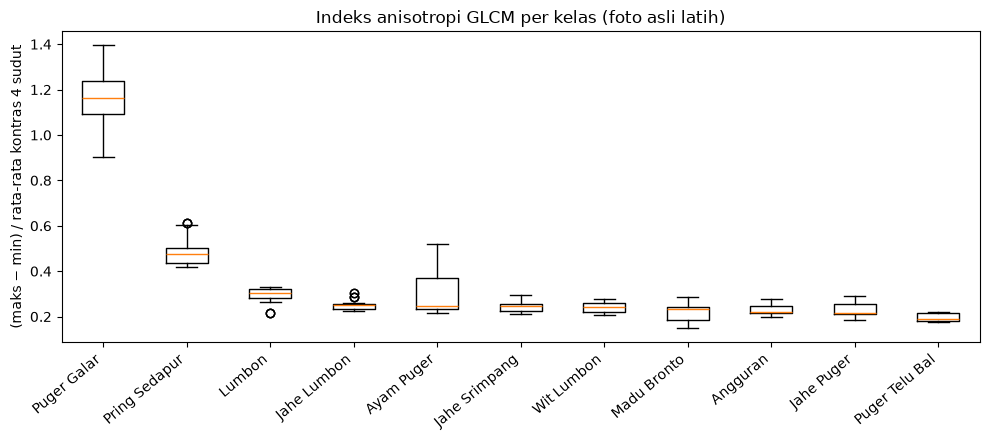

In [18]:
order = summary.index.tolist()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([aniso.loc[aniso["label"] == c, "anisotropi"] for c in order], showfliers=True)
ax.set_xticks(range(1, len(order) + 1), order, rotation=40, ha="right")
ax.set_ylabel("(maks − min) / rata-rata kontras 4 sudut")
ax.set_title("Indeks anisotropi GLCM per kelas (foto asli latih)")
fig.tight_layout()
fig.savefig(FIG_DIR / "anisotropi_per_kelas.png", dpi=150)
plt.show()

In [19]:
top2 = summary["median"].iloc[:2]
rest = summary["median"].iloc[2:]
print(f"Peringkat 1: {top2.index[0]} (median {top2.iloc[0]:.3f})")
print(f"Peringkat 2: {top2.index[1]} (median {top2.iloc[1]:.3f})")
print(f"Kelas lain : median {rest.min():.3f} – {rest.max():.3f}")
print(f"Rasio peringkat 1 / peringkat 2: {top2.iloc[0] / top2.iloc[1]:.1f}x")
lo1 = aniso.loc[aniso["label"] == top2.index[0], "anisotropi"].min()
hi_others = aniso.loc[aniso["label"] != top2.index[0], "anisotropi"].max()
print(f"Nilai terkecil {top2.index[0]}: {lo1:.3f}; nilai terbesar kelas lain: {hi_others:.3f}")

Peringkat 1: Puger Galar (median 1.162)
Peringkat 2: Pring Sedapur (median 0.474)
Kelas lain : median 0.191 – 0.302
Rasio peringkat 1 / peringkat 2: 2.5x
Nilai terkecil Puger Galar: 0.902; nilai terbesar kelas lain: 0.614


### Keputusan: kelas pantauan H3 = Puger Galar

Dikonfirmasi pada 24-11-2026, **sebelum** ada hasil model apa pun, dan hanya berdasarkan foto asli data latih. Dicatat di `config.H3_CLASS` dan bagian *Status* `CLAUDE.md`.

**Alasan.**

1. **Secara visual paling berarah.** Pada lembar kontak, Puger Galar adalah satu-satunya kelas yang latarnya berupa garis-garis lurus sejajar dan rapat (*galar*, bilah bambu). Motif lain didominasi bentuk melengkung (sulur, daun, bunga) atau pola simetris yang tidak punya satu arah dominan. Pring Sedapur memang punya bentuk memanjang (daun bambu), tetapi arahnya bercampur dalam satu foto, sehingga hanya dijadikan pembanding.
2. **Arah garisnya berbeda antar-foto.** Kain dibentang di lantai dengan posisi yang tidak seragam, sehingga garis galar tampak diagonal di satu foto dan vertikal di foto lain. Ini kasus paling pas untuk menguji kelemahan GLCM 0° (S1): GLCM 0° hanya membandingkan piksel dengan tetangga di kanannya, sehingga motif yang sama menghasilkan nilai yang berbeda tergantung arah garis. GLCM yang dirata-rata 4 arah (S2) seharusnya lebih stabil terhadap perbedaan ini.
3. **Didukung indeks anisotropi.** Indeks `(maks − min) / rata-rata` kontras GLCM di 4 sudut mengikuti gagasan Haralick dkk. (1973), yang mengusulkan *range* tiap ukuran GLCM di empat arah sebagai fitur. Pada sel sebelumnya, nilai terkecil Puger Galar masih lebih besar daripada nilai terbesar kelas lain mana pun. Artinya tidak ada satu pun foto latih dari kelas lain yang seberarah foto Puger Galar yang paling lemah.

**Status dan batasan.** Pemilihan ini adalah dugaan yang akan diuji, bukan hasil. Indeks anisotropi adalah alat bantu yang disusun untuk proyek ini dan belum divalidasi di literatur sebagai cara memilih kelas; dasar utamanya tetap penilaian visual sesuai desain. Prediksi yang diuji di notebook 04: *jika* informasi arah membantu, recall Puger Galar pada S2 lebih tinggi daripada S1. Kalau ternyata tidak, itu tetap temuan yang sah.

**Kenapa dikunci sekarang.** Kalau kelas pantauan dipilih setelah melihat hasil, kita bisa tergoda menunjuk kelas mana pun yang kebetulan menunjukkan S2 > S1. Dengan menguncinya sebelum ada model, uji ini tetap jujur.

In [20]:
assert config.H3_CLASS == summary.index[0], "H3_CLASS tidak sama dengan kelas berindeks anisotropi tertinggi"
print("Kelas pantauan H3:", config.H3_CLASS)

Kelas pantauan H3: Puger Galar


In [21]:
print(f"Waktu jalan notebook: {time.time() - t0:.0f} detik")

Waktu jalan notebook: 36 detik
